In [7]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

Outputs = Path(r"C:\Users\Soumya_SRB\Desktop\L&T Project Intelligencee\Outputs")

data = joblib.load(Outputs / "prepared_data.joblib")
models = joblib.load(Outputs / "trained_models.joblib")

X_test = data["X_test"]
y_test = data["y_test"]
forest_model = models["forest_model"]

print("Model and test data loaded successfully.")

Model and test data loaded successfully.


In [8]:
## 6.Model Interpretation and Prediction.

# Get the trained Random Forest classifier.
rf = forest_model.named_steps["classifier"]

# Get the feature names after preprocessing
feature_names = forest_model.named_steps[
    "preprocessor"].get_feature_names_out()

# Create a table of feature importance
importance_df = pd.DataFrame(
    {"Feature": feature_names,
    "Importance": rf.feature_importances_})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False)

display(importance_df.head(10))

,Feature,Importance
1,numeric__Project_Progress_Percent,0.104616
3,numeric__Cost_Used_Percent,0.097705
0,numeric__Planned_Duration_Months,0.086641
4,numeric__Number_of_Workers,0.082905
2,numeric__Budget_Million_DZD,0.081281
25,categorical__Material_Availability_Low,0.046456
33,categorical__Supplier_Delay_No,0.039986
34,categorical__Supplier_Delay_Yes,0.039901
5,numeric__Safety_Incidents,0.038881
30,categorical__Weather_Risk_High,0.035517


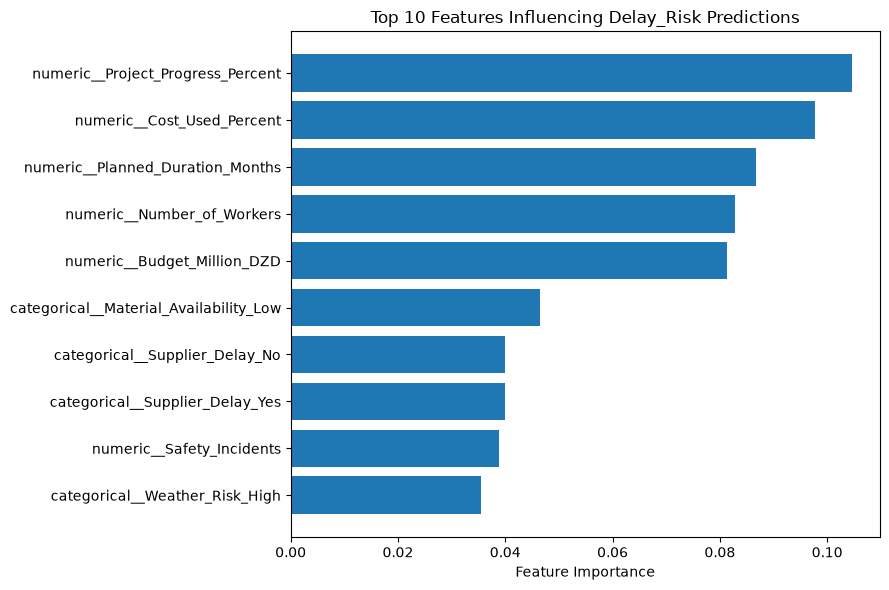

In [9]:
## Visualise the important features.
top_features = importance_df.head(10).sort_values(
    by="Importance")

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"])

plt.title("Top 10 Features Influencing Delay_Risk Predictions")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [10]:
## Predict risk for a new project.

# Select one test project.
sample_project = X_test.iloc[[0]]

# Predict its delay risk.
predicted_risk = forest_model.predict(sample_project)[0]

# Get prediction probabilities.
probabilities = forest_model.predict_proba(sample_project)[0]

print("Project details:")
display(sample_project)

print("Predicted delay risk:", predicted_risk)

for label, probability in zip(
    forest_model.classes_,
    probabilities):
    print(f"Probability of {label}: {probability:.2%}")

Project details:


,Project_Type,Region,Planned_Duration_Months,Project_Progress_Percent,Budget_Million_DZD,Cost_Used_Percent,Number_of_Workers,Material_Availability,Equipment_Availability,Weather_Risk,Supplier_Delay,Project_Complexity,Safety_Incidents
190,Road,Maharashtra,36,81,1463.27,29.5,448,Medium,Medium,Medium,No,Medium,1


Predicted delay risk: No
Probability of No: 93.50%
Probability of Yes: 6.50%


In [11]:
## Compare prediction with the actual label.
actual_risk = y_test.iloc[0]

print("Actual risk label:", actual_risk)
print("Predicted risk label:", predicted_risk)

if actual_risk == predicted_risk:
    print("Prediction matches the dataset label.")
else:
    print("Prediction does not match the dataset label.")

Actual risk label: No
Predicted risk label: No
Prediction matches the dataset label.


In [13]:
from pathlib import Path

Outputs = Path(r"C:\Users\Soumya_SRB\Desktop\L&T Project Intelligencee\Outputs")
Outputs.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(
    Outputs / "feature_importance.csv",
    index=False)

print("Feature importance saved successfully.")

Feature importance saved successfully.
